In [7]:

#by Henry Schumacher
#-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-#

#-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-#
import os
import sys
import json
import uuid
import tqdm
# import h5py
import math
# import xraydb
import plotly
#-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-#
import numpy as np
import pandas as pd
# import pyxray as xy
# import odrpack as odr
lazy import seaborn as sb
#-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-#
import matplotlib.pyplot as plt
from matplotlib import ticker
from matplotlib.gridspec import GridSpec
from scipy.signal import find_peaks
from scipy.optimize import curve_fit
from getmac import get_mac_address as gma
from itertools import chain
from matplotlib.offsetbox import OffsetImage, AnnotationBbox, TextArea, VPacker
#-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-#
from colors import load_colors
from PIXE_functions import *
from PWBA_ECPSSR_cross import *
#-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-#

from matplotlib import rc
# rc('font',**{'family':'sans-serif','sans-serif':['Helvetica']})
## for Palatino and other serif fonts use:
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times"],
    "text.usetex": True,
    "font.size": 8,
    "pgf.rcfonts": False
})


plt.rcParams.update({
    "pgf.texsystem": "pdflatex",
    "pgf.preamble": "\n".join([
          r'\usepackage{amsmath}',
     ]),
})

#-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-#
color_schemes = load_colors()

#-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-o-#

In [8]:
def PWBA_single_elem(E_range:list, M2_u:float, Z2:int, edge:str):
    E_list = np.linspace(E_range[0],E_range[1],E_range[2])
    PWBA_list = test_PWBA_range(E1_MeV_range=E_list, M1_u=1.007276, M2_u=M2_u, Z1=1, Z2=Z2, edge=edge)
    # for E in tqdm.tqdm(E_list):
    #     PWBA_list.append(test_PWBA_range(E1_MeV_range=E, M1_u=1.007276, M2_u=M2_u, Z1=1, Z2=Z2, n=EDGE_N[edge], edge=edge))
    return PWBA_list

In [9]:
def ionization_2_production(sigma:float, elem:str, edge:str):
    '''
    Coster-Krönig Yields: Krause_1979a
    fij M-shell Cohen_2015 and Kaur_2014
    
    '''
    
    omega_K = xy.xray_edges(elem)['K'].fyield
    omega_1 = xy.xray_edges(elem)['L1'].fyield
    omega_2 = xy.xray_edges(elem)['L2'].fyield
    omega_3 = xy.xray_edges(elem)['L3'].fyield
    f12 = xy.ck_probability(elem, 'L1', 'L2')
    f13 = xy.ck_probability(elem, 'L1', 'L3')
    f23 = xy.ck_probability(elem, 'L2', 'L3')
    
    if edge == 'K':
        return omega_K*sigma
    elif edge == 'L1':
        return (omega_1 + f12*omega_2 + (f13 + (f12*f23))*omega_3) * sigma
    elif edge == 'L2':
        return (omega_2 + f23*omega_3) * sigma
    elif edge == 'L3':
        return omega_3 * sigma
    elif edge == 'M1':
        return xy.xray_edges(elem)['M1'].fyield * sigma
    raise ValueError(f'No fluorescence yield treatment for edge {edge}')

In [10]:
def single_element_data_plot(data:dict, start_val:list, elem:str, fmt:list):
    
    if (fmt[0] == 'normal'):
        figsize = (6,4)
        DPI = 250
        fontsize = 6
    elif (fmt[0] == 'presentation'):
        figsize = (6,4)
        DPI = 180
        fontsize = 8
    elif (fmt[0] == 'onepage'):
        figsize = (8,4)
        DPI = 250
        fontsize = 6
    
    data_x = np.array(data[elem]["energy"])
    data_y_ecpssr = np.array(data[elem]["ecpssr"])
    data_y_ref = np.array(data[elem]["reference"])
    
    print(data_x)
    print(data_y_ecpssr)
    print(data_y_ref)
    
    data_x_err = np.array([0.05]*len(data_x))
    data_y_err = np.array(data[elem]["error"]*data_y_ref)*0.01
    data_y_err_ecpssr = np.ones(len(data_y_ecpssr))*data_y_err[0]*0.5
    
    beta_ecpssr = evaluator_scipy(func=poly4_func, beta0_list=start_val, x=data_x, y=data_y_ecpssr, xerr=data_x_err, yerr=data_y_err_ecpssr)
    beta_export_ecpssr = [beta_ecpssr['param'],beta_ecpssr['errors']]
    
    beta_ref = evaluator_scipy(func=poly4_func, beta0_list=start_val, x=data_x, y=data_y_ref, xerr=data_x_err, yerr=data_y_err)
    beta_export_ref = [beta_ref['param'],beta_ref['errors']]
    
    
    PWBA_cross_section_K = PWBA_single_elem([0.2,15,250], 26.9815, 13, edge='K')
    # PWBA_cross_section_L1 = PWBA_single_elem([0.2,15,250], 26.9815, 13, edge='L1')    
    
    xlin = np.linspace(0, np.max(data_x)+1, 2000)
    xlin_pwba = np.linspace(0.2,15,250)
    
    _, ax = plt.subplots(figsize=figsize, dpi=DPI)
    ax.errorbar(data_x, data_y_ecpssr, xerr=data_x_err,
                fmt='o',markersize=2.5,lw=0.5,color='#aa0022', zorder=3, label=r'$\sigma_{\mathrm{ECPSSR}}^K$')
    ax.errorbar(data_x, data_y_ref, xerr=data_x_err, yerr=data_y_err,
                fmt='x',markersize=3,lw=0.5,color='#4488ff', zorder=3, label=r'$\sigma_{\mathrm{exp}}^K$')
    
    ax.plot(xlin, poly4_func(beta_export_ecpssr[0],xlin),
            color='black',lw=0.75,ls='-',zorder=2, label='ECPSSR based fit')
    ax.plot(xlin, poly4_func(beta_export_ref[0],xlin),
            color='black',lw=0.75,ls='-.',zorder=2, label='exp. data based fit')
    
    ax.plot(xlin, poly4_func(beta_export_ref[0]-beta_export_ref[1],xlin),color='black',lw=0.3,ls='-.', label=r'exp. data based fit $\pm1\sigma$')
    ax.plot(xlin, poly4_func(beta_export_ref[0]+beta_export_ref[1],xlin),color='black',lw=0.3,ls='-.')
    ax.plot(xlin, poly4_func(beta_export_ecpssr[0]-beta_export_ecpssr[1],xlin),color='black',lw=0.3,ls='-', label=r'ECPSSR based fit $\pm1\sigma$')
    ax.plot(xlin, poly4_func(beta_export_ecpssr[0]+beta_export_ecpssr[1],xlin),color='black',lw=0.3,ls='-')
    
    ax.fill_betweenx([0,1e7],7,14,alpha=0.2,color='black',zorder=3)
    ax.text(x=14,y=1.1*min(np.min(data_y_ecpssr),np.min(data_y_ref)),s=r'$h=3$',zorder=4,ha="right",va="top",rotation=90,alpha=0.75)
    
    ax.fill_betweenx([0,1e7],0.75,1.75,alpha=0.2,color='black',zorder=3,label='Cyclotron accessible regimes')
    ax.text(x=1.75,y=1.1*min(np.min(data_y_ecpssr),np.min(data_y_ref)),s=r'$h=9$',zorder=4,ha="right",va="top",rotation=90,alpha=0.75)
    
    
    ax.plot(xlin_pwba,PWBA_cross_section_K, color='black', ls='--', lw=0.5, label='PWBA cross section K shell', zorder=3)
    # ax.plot(xlin_pwba,PWBA_cross_section_L1, color='black', ls=':', lw=0.5, label='PWBA cross section L1 shell', zorder=3)
    # ax.fill_between(xlin,poly4_func(beta_export_ecpssr[0]-beta_export_ecpssr[1],xlin),poly4_func(beta_export_ecpssr[0]+beta_export_ecpssr[1],xlin), alpha=0.1, color='#aa0022',zorder=2)
    # ax.fill_between(xlin,poly4_func(beta_export_ref[0]-beta_export_ref[1],xlin),poly4_func(beta_export_ref[0]+beta_export_ref[1],xlin), alpha=0.1, color='#1314de',zorder=2)
        
    ax.set_xlabel('Energy / MeV')
    ax.set_ylabel(r'cross section / b ($= 10^{-28}$cm²)')
    
    # ax.set_xlim(0.1,np.max(data_x)+2)
    ax.set_xlim(0.1,15)
    ax.set_ylim(0.75*min(np.min(data_y_ecpssr),np.min(data_y_ref)),1.4*max(np.max(data_y_ecpssr),np.max(data_y_ref)))
    
    ax.set_xscale(fmt[1])
    ax.set_yscale('log')
    
    ax.legend(ncols=2, fontsize=fontsize)

    ax.xaxis.grid(True, which='major', linestyle='-', linewidth=0.6)
    ax.xaxis.grid(True, which='minor', linestyle=':', linewidth=0.4)
    ax.yaxis.grid(True, which='major', linestyle='-', linewidth=0.6)
    ax.yaxis.grid(True, which='minor', linestyle=':', linewidth=0.4)
    plt.tight_layout()
    plt.show()
    return 'lol'

In [22]:
def single_element_all_cross(elem:str, energy_range:list, fmt:list):
    
    element_mass = xy.atomic_mass(element=elem)
    element_charge = xy.atomic_number(element=elem)
        
    if (fmt[0] == 'normal'):
        figsize = (6,4)
        DPI = 250
        fontsize = 6
    elif (fmt[0] == 'presentation'):
        figsize = (6,4)
        DPI = 180
        fontsize = 8
    elif (fmt[0] == 'onepage'):
        figsize = (8,4)
        DPI = 250
        fontsize = 6
    
    element_edges = xy.xray_edges(element=elem)
    
    element_edges_list = [e for e in element_edges.keys() if element_edges[e].fyield != 0]
    element_edges_fyields = [element_edges[e].fyield for e in element_edges_list]
    
    print('='*40)
    print(f'SHELLS in {elem}: {element_edges_list}')
    print(f'F.YIELDS: {element_edges_fyields}')
    print('='*40)
    
    PWBA_cross_section = {}
    for e in range(0,5): # CHANGE TO LEN(LIST)
        edge = element_edges_list[e]
        # if edge[0] != 'M' and edge[0] != 'N':
        print(f'NOW CALCULATING PWBA FOR SHELL: {edge}')
        print('='*40)
        pwba_results = PWBA_single_elem(energy_range, element_mass, element_charge, edge=edge)
        PWBA_cross_section[edge] = ionization_2_production(pwba_results, elem, edge)
        print(f'PWBA CALCULATION: {round((e+1)/len(element_edges_list)*100,2)} % DONE.')
        print('='*40)
        
    xlin = np.linspace(energy_range[0],energy_range[1],energy_range[2])
    
    _, ax = plt.subplots(figsize=figsize, dpi=DPI)
       
    max_value, min_value = 0, 1e30
    for edge in list(PWBA_cross_section.keys()):
        # print(PWBA_cross_section[edge])
        if np.max(PWBA_cross_section[edge]) > max_value:
            max_value = np.max(PWBA_cross_section[edge]) 
        if np.min(PWBA_cross_section[edge]) < min_value:
            min_value = np.min(PWBA_cross_section[edge])
        ax.plot(xlin,PWBA_cross_section[edge], ls='-', lw=0.5, label=r'$\sigma_{\mathrm{PWBA}}$ ' + f'{edge} shell', zorder=3)

    if min_value < 1:
        ypos = 10*min_value
    else:
        ypos = 1.1*min_value
    
    ax.fill_betweenx([0,1e20],7,14,alpha=0.2,color='black',zorder=3)
    ax.text(x=14,y=ypos,s=r'$h=3$',zorder=4,ha="right",va="top",rotation=90,alpha=0.75)
    
    ax.fill_betweenx([0,1e20],0.75,1.75,alpha=0.2,color='black',zorder=3,label='Cyclotron accessible regimes')
    ax.text(x=1.75,y=ypos,s=r'$h=9$',zorder=4,ha="right",va="top",rotation=90,alpha=0.75)

    ax.set_ylim(min_value*0.5,max_value*2.5)
    
    ax.set_xlabel('Energy / MeV')
    ax.set_ylabel(r'X-ray production cross section / b ($= 10^{-28}$cm²)')
    
    ax.set_xscale(fmt[1])
    ax.set_yscale('log')
    
    ax.legend(ncols=2, fontsize=fontsize, loc='upper left')

    ax.xaxis.grid(True, which='major', linestyle='-', linewidth=0.6)
    ax.xaxis.grid(True, which='minor', linestyle=':', linewidth=0.4)
    ax.yaxis.grid(True, which='major', linestyle='-', linewidth=0.6)
    ax.yaxis.grid(True, which='minor', linestyle=':', linewidth=0.4)
    plt.tight_layout()
    plt.show()
    return 'OMEGA_LOL'

SHELLS in Tb: ['K', 'L1', 'L2', 'L3', 'M1', 'M2', 'M3', 'M4', 'M5', 'N1', 'N2', 'N3', 'N4', 'N5']
F.YIELDS: [0.969464, 0.083, 0.167, 0.164, 0.000975, 0.00166, 0.001355, 0.0054, 0.00825, 3.3e-05, 7e-05, 5.6e-05, 0.00011, 0.00011]
NOW CALCULATING PWBA FOR SHELL: K


100%|██████████| 200/200 [00:01<00:00, 162.63it/s]


PWBA CALCULATION: 7.14 % DONE.
NOW CALCULATING PWBA FOR SHELL: L1


100%|██████████| 200/200 [00:02<00:00, 98.24it/s] 


PWBA CALCULATION: 14.29 % DONE.
NOW CALCULATING PWBA FOR SHELL: L2


100%|██████████| 200/200 [00:01<00:00, 107.42it/s]


PWBA CALCULATION: 21.43 % DONE.
NOW CALCULATING PWBA FOR SHELL: L3


100%|██████████| 200/200 [00:01<00:00, 108.61it/s]


PWBA CALCULATION: 28.57 % DONE.
NOW CALCULATING PWBA FOR SHELL: M1


100%|██████████| 200/200 [00:02<00:00, 75.71it/s]


PWBA CALCULATION: 35.71 % DONE.


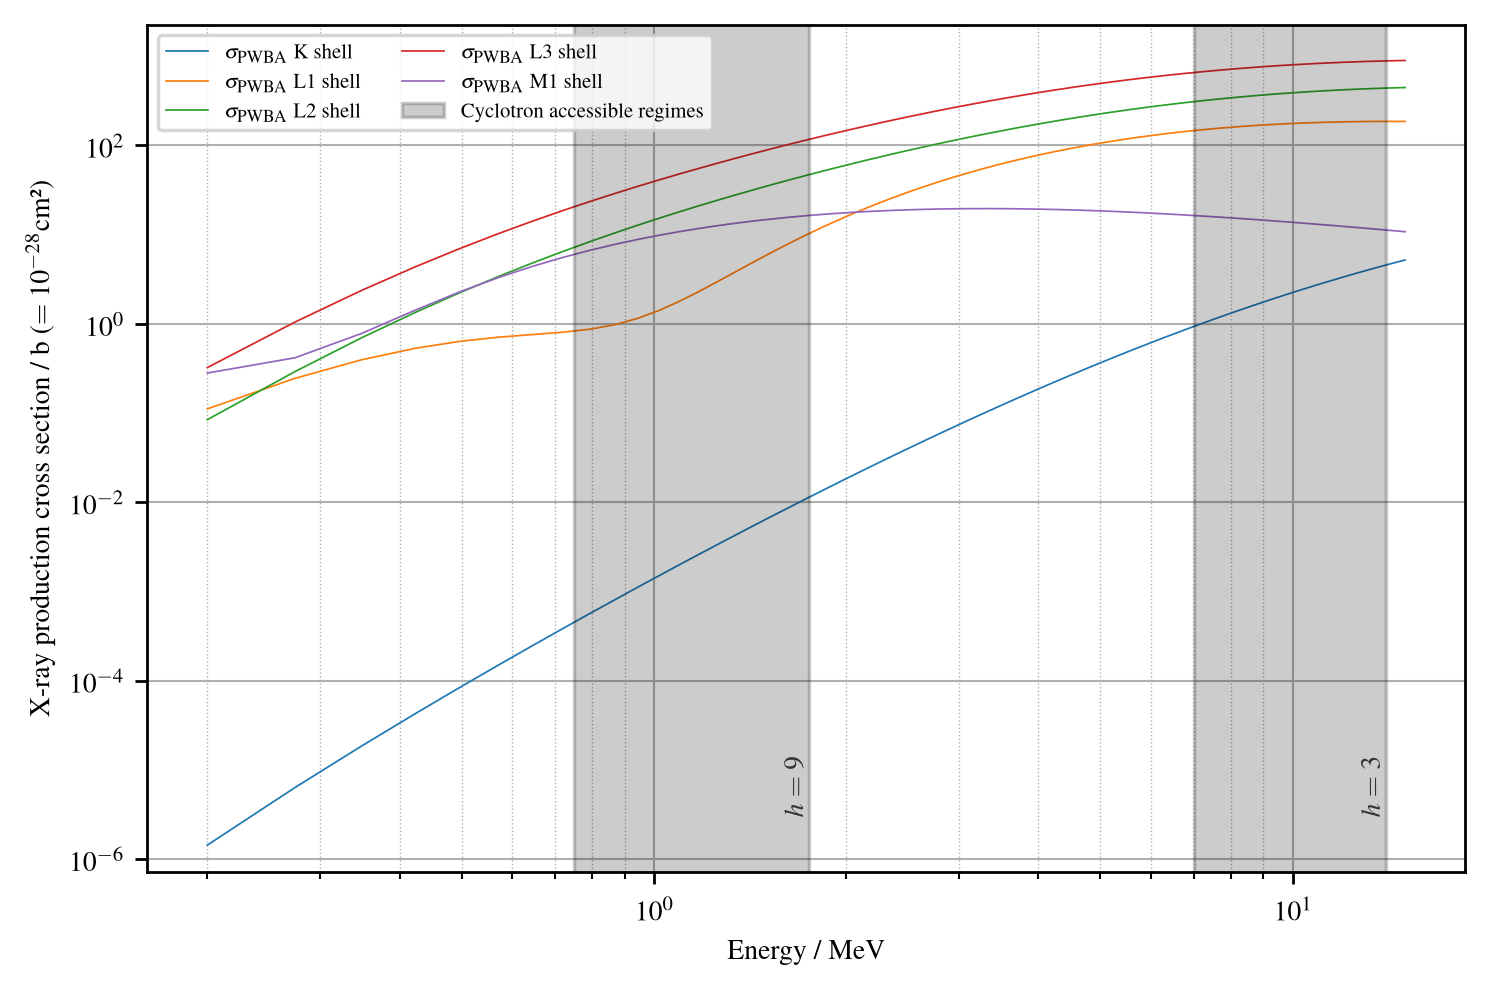

'OMEGA_LOL'

In [23]:
single_element_all_cross(elem='Tb', energy_range=[0.2,15,200], fmt=['normal','log'])

# s_val = [0,0,1,0,1]
# single_element_data_plot(data=full_pixe_data, start_val=s_val, elem='Si', fmt=['normal','log'])